# Step 3: Preprocessing, Normalization & Scaling

**Dataset:** `data/trends_cleaned.csv`  
**Goal:** Scale numeric columns, convert categories and True/False flags into numbers, compare data before vs. after scaling, and save `data/trends_processed.csv`.


## 1. Load Cleaned Data


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

df = pd.read_csv("data/trends_cleaned.csv")
print("Loaded dataset shape:", df.shape)
df.head()


Loaded dataset shape: (26945, 11)


,location,year,category,rank,query,category_clean,script,is_global,query_len,query_word_count,is_length_outlier
0,Global,2001,Consumer Brands,1,Nokia,consumer brands,Latin,True,5,1,False
1,Global,2001,Consumer Brands,2,Sony,consumer brands,Latin,True,4,1,False
2,Global,2001,Consumer Brands,3,BMW,consumer brands,Latin,True,3,1,False
3,Global,2001,Consumer Brands,4,Palm,consumer brands,Latin,True,4,1,False
4,Global,2001,Consumer Brands,5,Adobe,consumer brands,Latin,True,5,1,False


## 2. Why This Dataset Needs Scaling

- `year` is between `2001` and `2020`, while `rank` is between `1` and `5`.
- `query_len` (`1` to `158`) and `query_word_count` (`1` to `22`) are right-skewed with long-query outliers.
- Scaling puts these columns on similar ranges so large numbers like `year` do not overpower small numbers like `rank` in machine learning models.


## 3. Scale Numeric Columns


In [2]:
df_proc = df.copy()

# Min-Max scaling (puts values between 0 and 1)
mm_scaler = MinMaxScaler()
df_proc[["year_scaled", "rank_scaled"]] = mm_scaler.fit_transform(df_proc[["year", "rank"]])

# Log transform + Standard scaling for skewed length columns
df_proc["query_len_log"] = np.log1p(df_proc["query_len"])
df_proc["query_words_log"] = np.log1p(df_proc["query_word_count"])

std_scaler = StandardScaler()
df_proc[["query_len_scaled", "query_words_scaled"]] = std_scaler.fit_transform(
    df_proc[["query_len_log", "query_words_log"]]
)

df_proc[["year", "year_scaled", "rank", "rank_scaled", "query_len", "query_len_scaled"]].describe().round(2)


,year,year_scaled,rank,rank_scaled,query_len,query_len_scaled
count,26945.00,26945.00,26945.00,26945.00,26945.00,26945.00
mean,2015.24,0.75,3.00,0.50,13.48,0.00
std,3.56,0.19,1.41,0.35,7.22,1.00
min,2001.00,0.00,1.00,0.00,1.00,-3.71
25%,2013.00,0.63,2.00,0.25,9.00,-0.50
50%,2016.00,0.79,3.00,0.50,13.00,0.17
75%,2018.00,0.89,4.00,0.75,17.00,0.67
max,2020.00,1.00,5.00,1.00,158.00,5.02


## 4. Before vs. After Scaling Graph


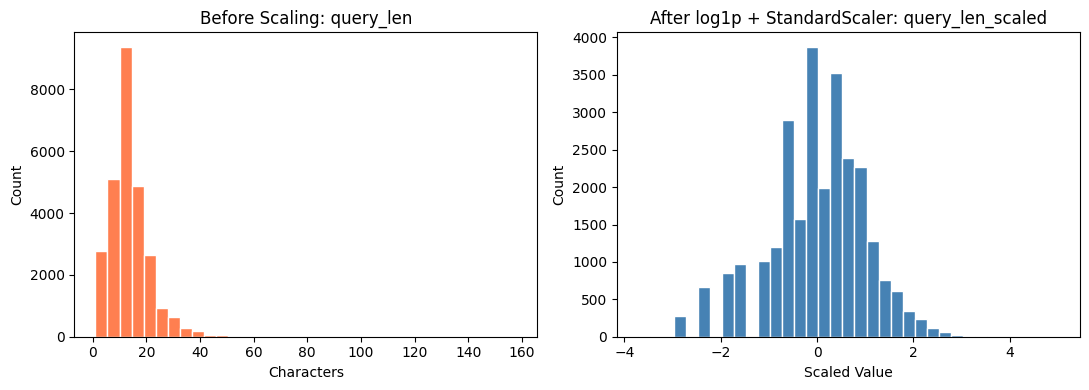

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df_proc["query_len"], bins=35, color="coral", edgecolor="white")
axes[0].set_title("Before Scaling: query_len")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Count")

axes[1].hist(df_proc["query_len_scaled"], bins=35, color="steelblue", edgecolor="white")
axes[1].set_title("After log1p + StandardScaler: query_len_scaled")
axes[1].set_xlabel("Scaled Value")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig("visualizations/07_before_after_scaling.png", dpi=150)
plt.show()


## 5. Convert Categories & True/False Columns to Numbers


In [4]:
# Convert text categories to integer codes
for col, new_col in [("location", "location_enc"), ("category_clean", "category_enc"), ("script", "script_enc")]:
    encoder = LabelEncoder()
    df_proc[new_col] = encoder.fit_transform(df_proc[col].astype(str))

# Convert True/False columns to 1 and 0
df_proc["is_global_int"] = df_proc["is_global"].astype(int)
df_proc["is_length_outlier_int"] = df_proc["is_length_outlier"].astype(int)

df_proc[["location", "location_enc", "script", "script_enc", "is_global", "is_global_int"]].head()


,location,location_enc,script,script_enc,is_global,is_global_int
0,Global,25,Latin,5,True,1
1,Global,25,Latin,5,True,1
2,Global,25,Latin,5,True,1
3,Global,25,Latin,5,True,1
4,Global,25,Latin,5,True,1


## 6. Save Processed Dataset


In [5]:
df_proc.to_csv("data/trends_processed.csv", index=False)
print("Saved processed data to data/trends_processed.csv")
print("Final shape:", df_proc.shape)


Saved processed data to data/trends_processed.csv
Final shape: (26945, 22)
